# Sprint 4 — Modelo de IA e MVP: inadimplência e recuperabilidade da dívida ativa de Palmas

**Projeto Integrador, Eixo II (BIINAR/UFT, 2026/2), Opção D — Grupo 1.** Notebook do entregável E3, executado do início ao fim por `python scripts/gerar_notebook_sprint4.py`.

> **Dados individuais sintéticos.** Os créditos de IPTU e os imóveis desta base são simulados (ADR-003 da Sprint 3) sobre os setores censitários reais de Palmas. A acurácia obtida demonstra que o pipeline funciona, não que o modelo funciona no mundo real, e nenhuma linha corresponde a um contribuinte.

## 1. Introdução

Este notebook percorre a trilha completa do aprendizado de máquina da Sprint 4, da exploração dos dados à avaliação final, e o faz chamando as funções de `pipeline/ml`, que são as mesmas usadas pelo comando `python treinar_sprint4.py`. Essa escolha evita duas versões da mesma lógica, porque uma regra escrita só no notebook poderia divergir da regra que gera os modelos versionados; desse modo, o notebook documenta e reproduz, e o pacote em `models/sprint4/v1` é a fonte única dos artefatos.

O trabalho responde a duas perguntas distintas, e a separação é deliberada. O **M1** estima, em 1º de janeiro, se o crédito do exercício ficará sem pagamento até o vencimento; o **M2** estima, numa fotografia da carteira, se um crédito já inscrito em dívida ativa e ainda aberto será pago nos 365 dias seguintes. Como população, momento de decisão e horizonte diferem, usar 1 − P(inadimplência) como recuperabilidade misturaria as perguntas, e por isso cada tarefa tem alvo, janela e modelo próprios.

O método segue o CRISP-ML(Q), que acrescenta garantia de qualidade a cada fase do CRISP-DM (Studer et al., 2021, DOI 10.3390/make3020020), e o protocolo, com janelas, atributos autorizados, grades e regras de decisão, foi fixado em `configs/sprint4.yaml` antes de qualquer contato com o teste. Por conseguinte, o teste é avaliado uma única vez, com modelo, limiar e calibração já congelados.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from pipeline.ml import artefatos, avaliacao, dados, experimento, figuras, modelos, pacote
from pipeline.ml.config import RAIZ

warnings.filterwarnings("ignore", message="Skipping features without any observed values")
# As threads do Random Forest (n_jobs=10) refazem a lista global de filtros de aviso (o scikit-learn chama
# resetwarnings() em cada uma), e o filtro acima pode sumir por um instante; por isso, um aviso que escape
# é mostrado sem o caminho do arquivo, e a saída publicada não traz caminho da máquina.
warnings.showwarning = lambda mensagem, categoria, *_, **__: print(f"{categoria.__name__}: {mensagem}", file=sys.stderr)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
FIGURAS = RAIZ / "reports" / "sprint4" / "figuras"
CONFERENCIA = RAIZ / "saida" / "notebook_sprint4" / "v1"
VERSIONADO = RAIZ / "models" / "sprint4" / "v1"

## 2. Ambiente, protocolo e base congelada

A reprodutibilidade começa pelo registro do que entra no experimento, porque um resultado sem a versão dos dados, do código e das bibliotecas não pode ser refeito (Amershi et al., 2019, DOI 10.1109/ICSE-SEIP.2019.00042). A célula abaixo carrega o protocolo, calcula o SHA-256 de cada insumo e mostra as versões do ambiente; o hash da base deve coincidir com o da execução de referência da Sprint 3, o que confirma que a Sprint 4 parte exatamente da base entregue.

In [2]:
ctx = experimento.preparar()
p = ctx.protocolo
display(pd.DataFrame({"insumo": list(ctx.insumos), "sha256": [h[:16] + "…" for h in ctx.insumos.values()]}))
print("protocolo", p.versao, p.sha256[:16], "· semente", p.semente, "· execução", ctx.execucao)
print("simulação", ctx.simulacao["assinatura"][:16], "· execução da Sprint 3", ctx.simulacao["execucao_sprint3"])
print(artefatos.ambiente())

,insumo,sha256
0,data/pronto/base_analitica_creditos.csv.gz,c45d7ea9b875fb59…
1,data/pronto/setores_socioeconomia.csv,66f8af16b5bfb1a7…
2,data/pronto/quadras_socioeconomia.csv,6265085137233a2d…
3,data/limpo/setores_ibge.csv,bb1c984fca36e9d0…
4,data/pronto/qualidade_dados.json,4840a4db30c192d2…


protocolo 1.0.0 33cc03e63d82ce8e · semente 20261107 · execução 20261108T043258-3bef93
simulação e66099c7d0c854ba · execução da Sprint 3 20261107T184930-2adc77
{'python': '3.14.7', 'sistema': 'Windows-11', 'scikit-learn': '1.9.1', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'joblib': '1.6.0'}


## 3. Qualidade da base

Antes de modelar, a base precisa ser verificada quanto a chave, tipos, ausências e coerência temporal, porque um erro nessa etapa se propaga a todos os modelos. A função `dados.carregar_base` já recusa crédito repetido e crédito sem vencimento; a tabela abaixo descreve o restante: volume por exercício, ausências por coluna e a coerência das datas de pagamento e de inscrição em relação ao vencimento.

In [3]:
base = ctx.base
print(f"{len(base):,} créditos · {base['id_imovel'].nunique():,} imóveis · exercícios {sorted(base['exercicio'].unique())}".replace(",", "."))
qualidade = pd.DataFrame({"ausentes": base.isna().sum(), "tipo": base.dtypes.astype(str)})
display(qualidade)
coerencia = {
    "inscrição antes do vencimento": int((base["data_inscricao"] < base["data_vencimento"]).sum()),
    "pagamento em dia com inadimplente = 1": int(((base["data_pagamento"] <= base["data_vencimento"]) & (base["inadimplente"] == 1)).sum()),
    "origem diferente de SINTETICO": int((base["origem_dado"] != "SINTETICO").sum()),
}
coerencia

556.260 créditos · 111.252 imóveis · exercícios [np.int64(2021). np.int64(2022). np.int64(2023). np.int64(2024). np.int64(2025)]


,ausentes,tipo
id_credito,0,int64
id_imovel,0,int64
exercicio,0,int64
data_vencimento,0,datetime64[us]
valor_principal_centavos,0,int64
inadimplente,0,int64
data_pagamento,78122,datetime64[us]
data_inscricao,455157,datetime64[us]
cd_setor,0,str
quintil_renda,0,int64


{'inscrição antes do vencimento': 0,
 'pagamento em dia com inadimplente = 1': 0,
 'origem diferente de SINTETICO': 0}

A base passa nas três verificações de coerência, e as ausências estão onde o domínio as explica: `data_pagamento` falta quando o crédito não foi pago até o corte, e `data_inscricao` falta quando o crédito nunca foi inscrito. Por isso, essas ausências não são erro de dado, mas informação de estado, e é justamente por carregarem o futuro que essas duas colunas ficam fora dos atributos e servem apenas à construção dos rótulos.

## 4. Fotografias em t0 e divisão temporal com controles contra vazamento (E1)

Um atributo só pode usar o que já era conhecido no momento da decisão; caso contrário, o modelo aprende com o futuro e parece excelente sem funcionar (Kaufman et al., 2012, DOI 10.1145/2382577.2382579; Kapoor e Narayanan, 2023, DOI 10.1016/j.patter.2023.100804). Por esse motivo, as fotografias são reconstruídas a partir dos eventos — vencimento, inadimplência no vencimento, pagamento e inscrição — em cada data t0, e as colunas de atraso, saldo e situação no corte da Sprint 3 nunca entram como atributo.

A divisão também segue datas, e não a posição das linhas: o M1 treina com os exercícios 2021–2023, valida em 2024 e testa em 2025; o M2 treina com as fotografias de 29/06/2022 e 30/06/2023, valida em 01/07/2024 e testa em 31/07/2025, cuja janela de 365 dias termina exatamente no corte. Roberts et al. (2017, DOI 10.1111/ecog.02881) mostram que a validação aleatória superestima o desempenho quando os dados têm estrutura temporal, e as invariantes abaixo garantem que todo rótulo usado num conjunto já estava disponível antes do primeiro t0 do conjunto seguinte.

In [4]:
divisoes = {t: experimento.conjuntos(ctx, t) for t in ("M1", "M2")}
linhas = []
for tarefa, d in divisoes.items():
    for nome, c in d.manifesto["conjuntos"].items():
        linhas.append({"tarefa": tarefa, "conjunto": nome, "n": c["n"], "imóveis": c["imoveis"], "positivos": c["positivos"],
                       "prevalência": c["prevalencia"], "períodos": c["periodos"], "fim do rótulo": c["fim_rotulo"]})
display(pd.DataFrame(linhas))
display(pd.DataFrame([{"tarefa": t, **r} for t, d in divisoes.items() for r in d.manifesto["invariantes"]]))

,tarefa,conjunto,n,imóveis,positivos,prevalência,períodos,fim do rótulo
0,M1,treino,333756,111252,102439,0.306928,"[2021, 2022, 2023]","[2021-03-10, 2023-03-10]"
1,M1,validacao,111252,111252,40289,0.362142,[2024],"[2024-03-10, 2024-03-10]"
2,M1,teste,111252,111252,40838,0.367077,[2025],"[2025-03-10, 2025-03-10]"
3,M2,treino,46536,28877,5622,0.120810,"[2022-06-29, 2023-06-30]","[2023-06-29, 2024-06-29]"
4,M2,validacao,49213,38367,5975,0.121411,[2024-07-01],"[2025-07-01, 2025-07-01]"
5,M2,teste,64017,46015,7585,0.118484,[2025-07-31],"[2026-07-31, 2026-07-31]"


,tarefa,invariante,passou,evidencia
0,M1,"chave (tarefa, id_credito, t0) única",True,0 repetida(s)
1,M1,cronologia treino → validação,True,último rótulo disponível em 2023-03-10 < prime...
2,M1,cronologia validação → teste,True,último rótulo disponível em 2024-03-10 < prime...
3,M1,rótulos maduros em treino,True,0 imaturo(s)
4,M1,duas classes em treino,True,"classes [0, 1]"
5,M1,rótulos maduros em validacao,True,0 imaturo(s)
6,M1,duas classes em validacao,True,"classes [0, 1]"
7,M1,rótulos maduros em teste,True,0 imaturo(s)
8,M1,duas classes em teste,True,"classes [0, 1]"
9,M2,"chave (tarefa, id_credito, t0) única",True,0 repetida(s)


As nove invariantes passam nas duas tarefas: a chave (tarefa, crédito, t0) não se repete, a cronologia entre treino, validação e teste é respeitada, nenhum rótulo imaturo entra e as duas classes estão presentes em cada conjunto. A prevalência do M1 sobe de 30,7% no treino para cerca de 36% na validação e no teste, porque 2021, o primeiro exercício simulado, não tem histórico de inadimplência; essa mudança de distribuição é real no dado e, por isso, deve aparecer na avaliação temporal, em vez de ser escondida por uma divisão aleatória.

O caso sentinela abaixo torna a regra de disponibilidade verificável: um pagamento posterior a t0 é inserido num crédito, e os atributos da fotografia t0 não podem mudar. O mesmo teste existe na suíte automatizada (`tests/ml/test_dados_tempo.py`).

In [5]:
foto_2025 = divisoes["M1"].conjuntos.teste
aberto = base.loc[(base["exercicio"] == 2024) & base["data_pagamento"].isna()].iloc[0]
alterada = base.copy()
alterada.loc[alterada["id_credito"] == aberto["id_credito"], "data_pagamento"] = pd.Timestamp("2025-06-01")  # depois de t0 = 01/01/2025
antes = dados.fotografia_m1(base, 2025, p.data_corte, ctx.regioes, ctx.versao_dados)
depois = dados.fotografia_m1(alterada, 2025, p.data_corte, ctx.regioes, ctx.versao_dados)
print("atributos idênticos após pagamento futuro:", antes[list(p.m1.atributos)].equals(depois[list(p.m1.atributos)]))

atributos idênticos após pagamento futuro: True


## 5. Análise exploratória no treino

A exploração usa apenas o treino, porque qualquer decisão tomada depois de olhar a validação ou o teste contamina a avaliação. Para o M1, a pergunta é se o histórico do imóvel carrega sinal sobre a inadimplência; para o M2, se algum atributo conhecido em t0 diferencia as dívidas que serão pagas.

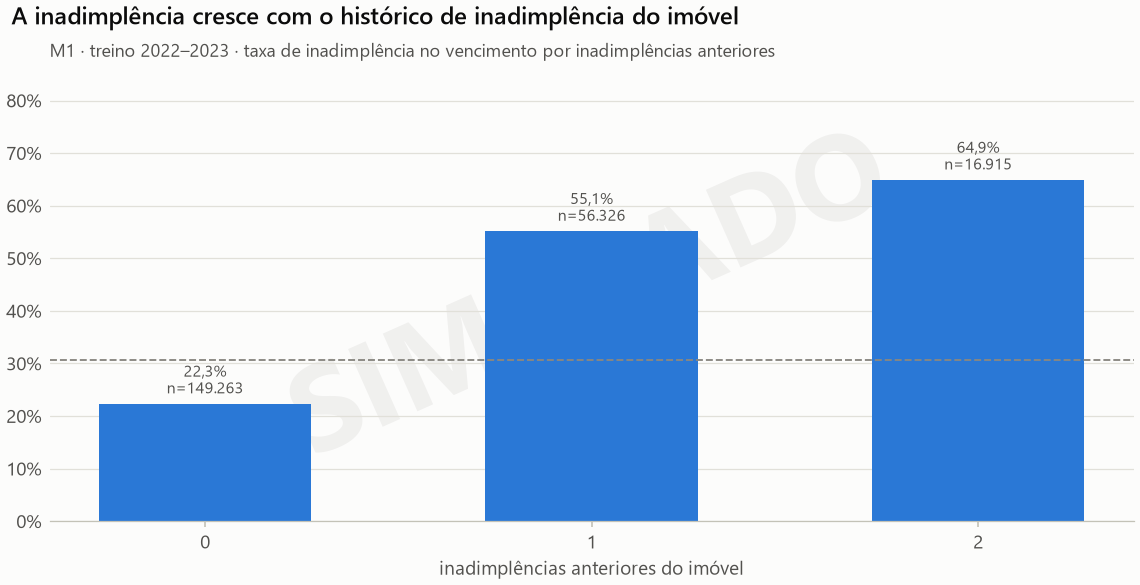

In [6]:
treino_m1, treino_m2 = divisoes["M1"].conjuntos.treino, divisoes["M2"].conjuntos.treino
media_m1 = float(treino_m1["alvo"].astype(float).mean())
tabela = figuras.taxa_por_atributo(treino_m1.loc[treino_m1["exercicio"] > 2021], "inadimplencias_anteriores")
fig = figuras.barras_taxa(tabela.sort_values("valor"), "A inadimplência cresce com o histórico de inadimplência do imóvel",
                          "M1 · treino 2022–2023 · taxa de inadimplência no vencimento por inadimplências anteriores",
                          "inadimplências anteriores do imóvel", media_m1)
display(Image(filename=figuras.salvar(fig, FIGURAS, "01_m1_historico.png")))

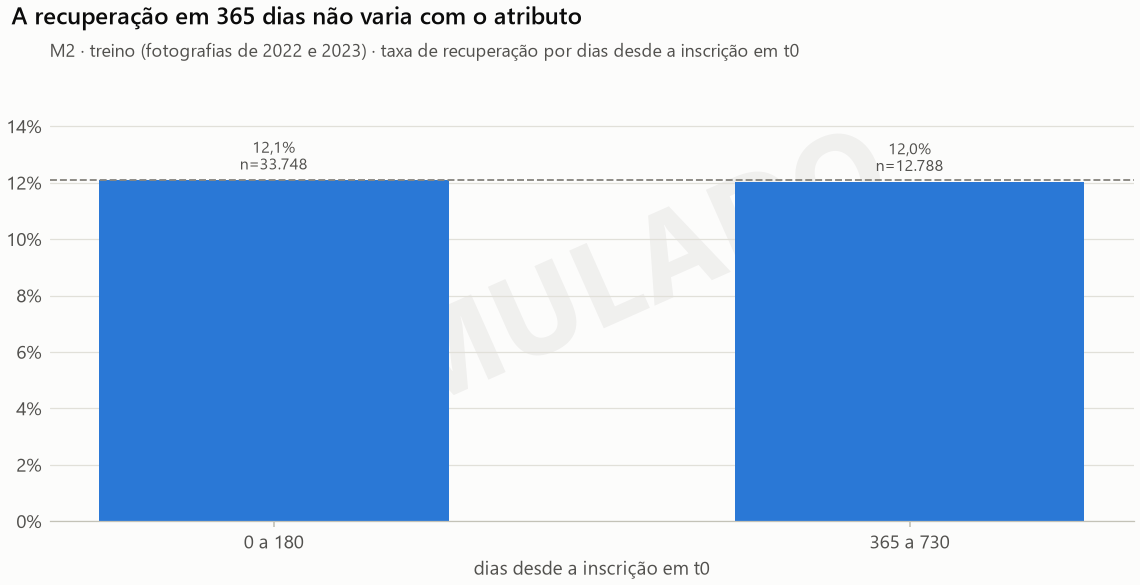

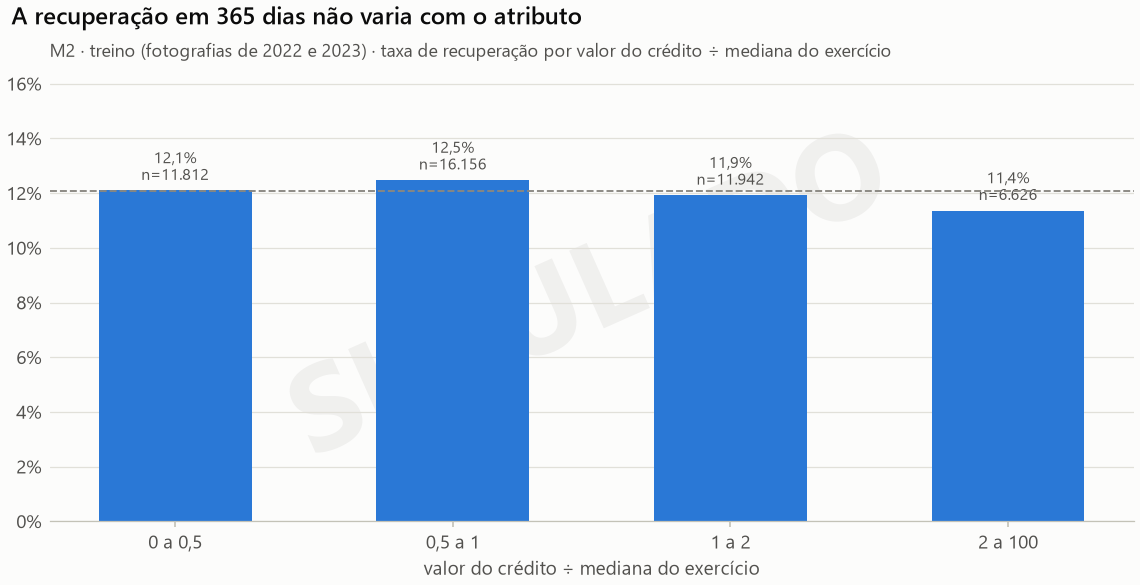

recuperação média no treino: 0.1208; parâmetro da simulação: 0,12 ao ano depois da inscrição


In [7]:
media_m2 = float(treino_m2["alvo"].astype(float).mean())
for atributo, faixas, nome, rotulo in (
        ("dias_desde_inscricao", [0, 180, 365, 730, 2000], "02_m2_tempo_inscricao.png", "dias desde a inscrição em t0"),
        ("valor_relativo_credito", [0, 0.5, 1, 2, 100], "03_m2_valor.png", "valor do crédito ÷ mediana do exercício")):
    tabela = figuras.taxa_por_atributo(treino_m2, atributo, faixas)
    fig = figuras.barras_taxa(tabela, "A recuperação em 365 dias não varia com o atributo",
                              f"M2 · treino (fotografias de 2022 e 2023) · taxa de recuperação por {rotulo}", rotulo, media_m2)
    display(Image(filename=figuras.salvar(fig, FIGURAS, nome)))
print(f"recuperação média no treino: {media_m2:.4f}; parâmetro da simulação: 0,12 ao ano depois da inscrição")

As duas explorações apontam para direções opostas, e essa diferença decorre do mecanismo que gerou os dados. No M1, a taxa de inadimplência cresce de forma nítida com o número de inadimplências anteriores, porque a simulação faz a inadimplência de um ano depender da do ano anterior (β = 1,5) e da renda do setor. No M2, a recuperação fica perto de 12% em todas as faixas, porque o gerador sorteia a espera até o pagamento depois da inscrição de uma distribuição exponencial com taxa anual constante de 0,12, sem relação com nenhum atributo; como a exponencial não tem memória, a chance de pagar nos próximos 365 dias é a mesma para toda dívida ainda aberta.

Por conseguinte, a expectativa registrada antes do treino é que o M2 não supere o preditor constante. Esse resultado, se confirmado, será publicado como achado, e o simulador não será alterado para produzir métricas favoráveis, porque ajustar o gerador depois de olhar o resultado transformaria o experimento em confirmação do que se quer ver (Morris, White e Crowther, 2019, DOI 10.1002/sim.8086).

## 6. Pré-processamento dentro do Pipeline

Toda transformação aprendida fica dentro de um `Pipeline` com `ColumnTransformer`, para que a mediana de imputação e a escala sejam estimadas só com os dados de ajuste de cada dobra; a documentação do scikit-learn resume a regra em nunca chamar `fit` nos dados de teste ("Common pitfalls", §12.2). Os atributos ausentes recebem a mediana do treino e um indicador de ausência, o que preserva a informação de que o imóvel não tinha exercício anterior; a escala é aplicada só à regressão logística, porque as árvores são invariantes a transformações monotônicas.

In [8]:
candidatos = modelos.candidatos(p, p.m1.atributos)
for nome, pipe in candidatos.items():
    print(f"{nome:22s}", " → ".join(f"{n}: {type(o).__name__}" for n, o in pipe.steps))
candidatos["regressao_logistica"]

dummy                  prep: ColumnTransformer → modelo: DummyClassifier
regressao_logistica    prep: ColumnTransformer → modelo: LogisticRegression
arvore_decisao         prep: ColumnTransformer → modelo: DecisionTreeClassifier
random_forest          prep: ColumnTransformer → modelo: RandomForestClassifier


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericos', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the 

## 7. Baselines, busca de hiperparâmetros e seleção (E1 e E2)

A comparação parte de referências simples, porque um modelo complexo só se justifica se superar o que uma regra trivial já faz. O `DummyClassifier` com a prevalência do treino é a referência mínima; a regressão logística e a árvore de decisão são os baselines exigidos; o Random Forest é o candidato de maior capacidade (Breiman, 2001, DOI 10.1023/A:1010933404324), com o número de árvores fixo em 200, porque o erro de generalização converge quando as árvores aumentam.

A busca usa `GridSearchCV` com as dobras temporais explícitas dentro do treino — 2021→2022 e 2021–2022→2023 no M1; 2022→2023 no M2 — e a métrica declarada no protocolo: Average Precision no M1, mais informativa que a curva ROC quando as classes são desbalanceadas (Saito e Rehmsmeier, 2015, DOI 10.1371/journal.pone.0118432), e Brier no M2, em que a probabilidade é o produto (Brier, 1950, DOI 10.1175/1520-0493(1950)078<0001:VOFEIT>2.0.CO;2). A escolha entre famílias usa a validação externa e a regra de um erro-padrão: entre os modelos a até um erro-padrão do melhor, fica o mais simples (Hastie, Tibshirani e Friedman, 2009, §7.10, DOI 10.1007/978-0-387-84858-7). O teste não participa de nenhuma dessas decisões, porque escolher e estimar o erro na mesma amostra enviesa a estimativa (Varma e Simon, 2006, DOI 10.1186/1471-2105-7-91).

In [9]:
treinos = {}
for tarefa in ("M1", "M2"):
    treinos[tarefa] = experimento.treinar(ctx, tarefa, divisoes[tarefa])
    t = treinos[tarefa]
    print(f"{tarefa}: escolhido = {t.selecao.escolhido}; supera o Dummy por mais de 1 erro-padrão = {t.selecao.supera_referencia}; "
          f"limiar (F1 máximo na validação) = {t.limiar:.4f}; calibração = {t.calibracao}")
    display(t.selecao.tabela.drop(columns=["segundos_busca"]).round(5))

M1: escolhido = regressao_logistica; supera o Dummy por mais de 1 erro-padrão = True; limiar (F1 máximo na validação) = 0.3069; calibração = {'recalibrado': False, 'motivo': 'M1 usa o limiar de decisão; a calibração é só diagnóstico'}


,modelo,metrica,validacao,erro_padrao,ic95_inf,ic95_sup,melhores_parametros,dentro_de_um_erro_padrao,escolhido
0,dummy,average_precision,0.36214,0.00142,0.35911,0.36446,{},False,False
1,regressao_logistica,average_precision,0.60129,0.00278,0.59602,0.60586,{'modelo__C': 10.0},True,True
2,arvore_decisao,average_precision,0.58678,0.00270,0.58159,0.59237,"{'modelo__max_depth': 10, 'modelo__min_samples...",False,False
3,random_forest,average_precision,0.60013,0.00278,0.59438,0.60552,"{'modelo__max_depth': 6, 'modelo__max_features...",True,False


M2: escolhido = regressao_logistica; supera o Dummy por mais de 1 erro-padrão = False; limiar (F1 máximo na validação) = 0.1023; calibração = {'desvio_medio_validacao': -0.002769426622185281, 'tolerancia': 0.02, 'recalibrado': False}


,modelo,metrica,validacao,erro_padrao,ic95_inf,ic95_sup,melhores_parametros,dentro_de_um_erro_padrao,escolhido
0,dummy,neg_brier_score,0.10667,0.00114,0.10414,0.10885,{},False,False
1,regressao_logistica,neg_brier_score,0.10668,0.00114,0.10415,0.10888,{'modelo__C': 0.1},True,True
2,arvore_decisao,neg_brier_score,0.10671,0.00114,0.10414,0.10889,"{'modelo__max_depth': 3, 'modelo__min_samples_...",True,False
3,random_forest,neg_brier_score,0.10671,0.00114,0.10419,0.10891,"{'modelo__max_depth': 6, 'modelo__max_features...",True,False


In [10]:
busca = pd.concat([b.tentativas.assign(tarefa=t) for t, tr in treinos.items() for b in tr.buscas.values()], ignore_index=True)
display(busca.sort_values(["tarefa", "modelo", "rank_test_score"]).groupby(["tarefa", "modelo"]).head(3)[
    ["tarefa", "modelo", "params", "mean_test_score", "std_test_score", "rank_test_score", "mean_fit_time"]].round(4))

,tarefa,modelo,params,mean_test_score,std_test_score,rank_test_score,mean_fit_time
9,M1,arvore_decisao,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.4300,0.1070,1,0.1364
8,M1,arvore_decisao,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.4296,0.1065,2,0.1402
7,M1,arvore_decisao,"{'modelo__max_depth': 6, 'modelo__min_samples_...",0.4293,0.1063,3,0.1248
0,M1,dummy,{},0.3386,0.0155,1,0.0952
12,M1,random_forest,"{'modelo__max_depth': 6, 'modelo__max_features...",0.4528,0.1298,1,3.4893
10,M1,random_forest,"{'modelo__max_depth': 6, 'modelo__max_features...",0.4525,0.1295,2,2.1388
13,M1,random_forest,"{'modelo__max_depth': 6, 'modelo__max_features...",0.4524,0.1293,3,3.4491
3,M1,regressao_logistica,{'modelo__C': 10.0},0.4525,0.1294,1,0.1258
2,M1,regressao_logistica,{'modelo__C': 1.0},0.4525,0.1294,2,0.1213
1,M1,regressao_logistica,{'modelo__C': 0.1},0.4525,0.1294,3,0.1467


No M1, a regressão logística foi a melhor família na validação e também a mais simples; o Random Forest ficou dentro de um erro-padrão dela, sem ganho que justificasse 200 árvores, e a árvore de decisão ficou abaixo. O ganho da logística sobre o Dummy é grande e estável no bootstrap por imóvel, o que confirma o sinal visto na exploração. No M2, todas as famílias empatam com o Dummy dentro de um erro-padrão; pela regra pré-especificada, a logística é mantida como o candidato mais simples, mas o registro `supera_referencia = False` documenta que nenhum modelo melhora a probabilidade constante. Como a média prevista ficou a menos de 2 pontos percentuais da observada na validação, a calibração adicional não foi aplicada.

## 8. Avaliação única no teste congelado (E2)

O teste é aberto agora, com modelo, limiar e calibração já fixados, e nenhuma decisão volta a ele. As métricas exigidas — acurácia, precisão, recall, F1 e matriz de confusão — vêm acompanhadas de n, prevalência e limiar, e são complementadas pela qualidade das probabilidades e pela precisão no topo do ranking. O TRIPOD+AI (Collins et al., 2024, DOI 10.1136/bmj-2023-078378), embora seja uma diretriz clínica, serve de roteiro de relato por analogia: população, momento da predição, desfecho, desempenho com incerteza e limitações.

In [11]:
avaliacoes = {t: experimento.avaliar(ctx, t, divisoes[t], treinos[t], pacote.VERSAO_MODELO) for t in ("M1", "M2")}
resumo = []
for tarefa, a in avaliacoes.items():
    c, pr, b = a.metricas["classificacao"], a.metricas["probabilidade"], a.metricas["bootstrap_metrica_principal"]
    resumo.append({"tarefa": tarefa, "modelo": a.metricas["modelo"], "n": c["n"], "prevalência": c["prevalencia"], "limiar": c["limiar"],
                   "acurácia": c["acuracia"], "precisão": c["precisao"], "recall": c["recall"], "F1": c["f1"],
                   "[[VN, FP], [FN, VP]]": c["matriz_confusao"], "AP": pr["average_precision"], "ROC-AUC": pr["roc_auc"],
                   "Brier": pr["brier"], "ganho de Brier": pr["ganho_brier_sobre_constante"],
                   f"IC95% {a.metricas['metrica_principal']}": [round(x, 4) for x in b["ic95"]]})
pd.DataFrame(resumo).round(4)

,tarefa,modelo,n,prevalência,limiar,acurácia,precisão,recall,F1,"[[VN, FP], [FN, VP]]",AP,ROC-AUC,Brier,ganho de Brier,IC95% average_precision,IC95% neg_brier_score
0,M1,regressao_logistica,111252,0.3671,0.3069,0.7111,0.5994,0.6425,0.6202,"[[52879, 17535], [14601, 26237]]",0.6061,0.7406,0.1909,0.1911,"[0.6008, 0.6111]",NaN
1,M2,regressao_logistica,64017,0.1185,0.1023,0.1240,0.1186,0.9938,0.2119,"[[400, 56032], [47, 7538]]",0.1225,0.5079,0.1044,0.0001,NaN,"[0.1024, 0.1062]"


,tarefa,modelo,escolhido,acuracia,precisao,recall,f1,average_precision,roc_auc,brier,ganho_brier_sobre_constante
1,M1,dummy,False,0.3671,0.3671,1.0000,0.5370,0.3671,0.5000,0.2359,0.0000
3,M1,regressao_logistica,True,0.7111,0.5994,0.6425,0.6202,0.6061,0.7406,0.1909,0.1911
5,M1,arvore_decisao,False,0.7197,0.6177,0.6201,0.6189,0.5888,0.7342,0.1924,0.1847
7,M1,random_forest,False,0.7024,0.5834,0.6621,0.6202,0.6024,0.7404,0.1909,0.1908
9,M2,dummy,False,0.1185,0.1185,1.0000,0.2119,0.1185,0.5000,0.1045,0.0000
11,M2,regressao_logistica,True,0.1240,0.1186,0.9938,0.2119,0.1225,0.5079,0.1044,0.0001
13,M2,arvore_decisao,False,0.1185,0.1185,1.0000,0.2119,0.1187,0.5011,0.1045,-0.0006
15,M2,random_forest,False,0.1349,0.1185,0.9785,0.2114,0.1181,0.5016,0.1045,-0.0005


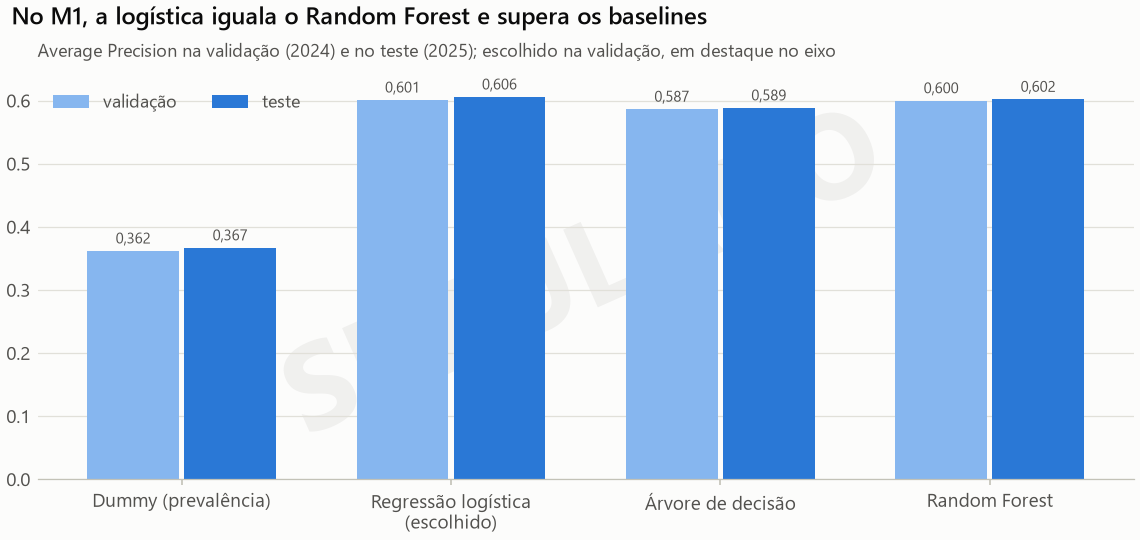

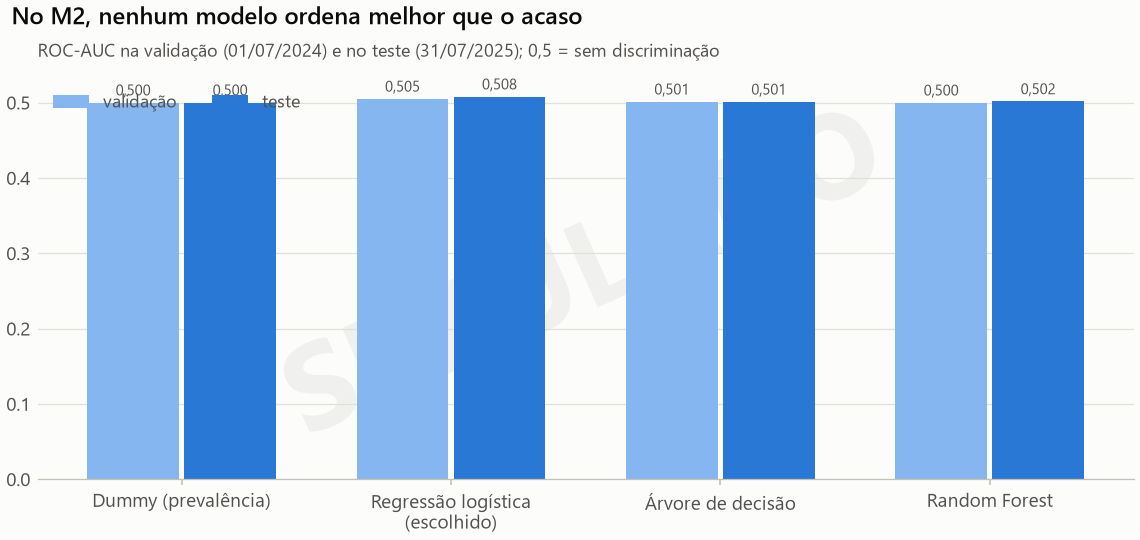

In [12]:
comparacao = pd.concat([a.comparacao.assign(tarefa=t) for t, a in avaliacoes.items()], ignore_index=True)
display(comparacao.loc[comparacao["conjunto"] == "teste", ["tarefa", "modelo", "escolhido", "acuracia", "precisao", "recall", "f1",
                                                           "average_precision", "roc_auc", "brier", "ganho_brier_sobre_constante"]].round(4))
fig = figuras.comparacao(comparacao, "M1", "average_precision", "No M1, a logística iguala o Random Forest e supera os baselines",
                         "Average Precision na validação (2024) e no teste (2025); escolhido na validação, em destaque no eixo")
display(Image(filename=figuras.salvar(fig, FIGURAS, "04_comparacao_m1.png")))
fig = figuras.comparacao(comparacao, "M2", "roc_auc", "No M2, nenhum modelo ordena melhor que o acaso",
                         "ROC-AUC na validação (01/07/2024) e no teste (31/07/2025); 0,5 = sem discriminação")
display(Image(filename=figuras.salvar(fig, FIGURAS, "05_comparacao_m2.png")))

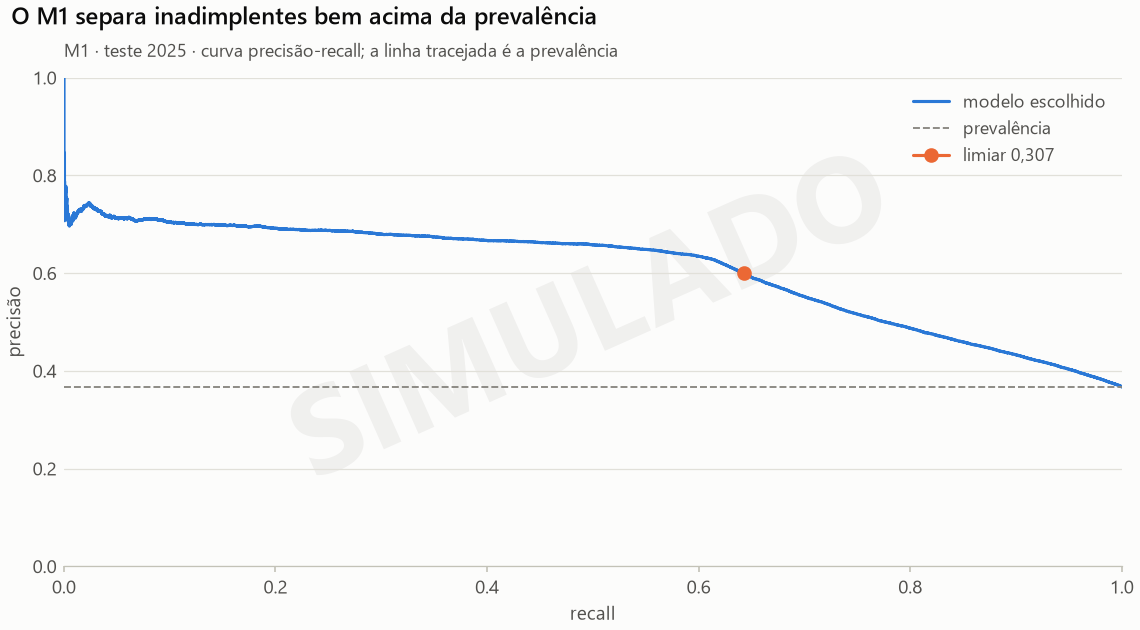

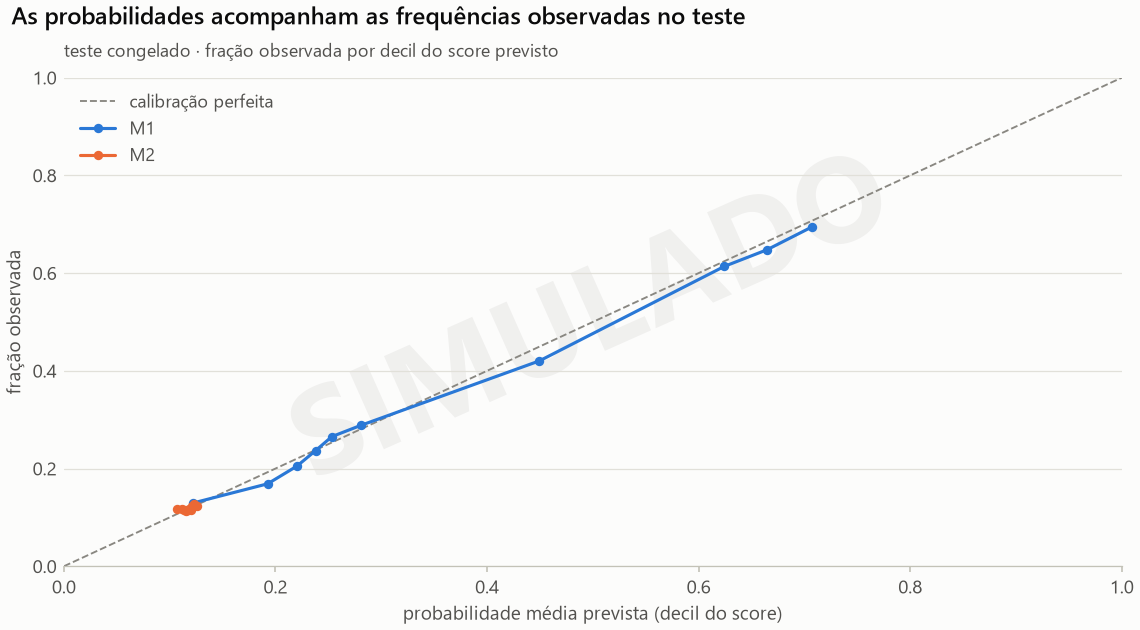

**M1: os k créditos de maior score**

,fracao,k,precisao_topo,recall_topo,principal_inadimplente_topo_centavos,fracao_principal_inadimplente
0,0.01,1113,0.7358,0.0201,16588025,0.0044
1,0.05,5563,0.7061,0.0962,152018123,0.0399
2,0.10,11125,0.6947,0.1893,337527116,0.0885
3,0.20,22250,0.6713,0.3657,784635190,0.2058


**M2: os k créditos de maior score**

,fracao,k,precisao_topo,recall_topo,principal_recuperado_topo_centavos,fracao_principal_recuperado
0,0.01,640,0.1422,0.0120,2148621,0.0041
1,0.05,3201,0.1265,0.0534,11766082,0.0222
2,0.10,6402,0.1236,0.1043,26714829,0.0504
3,0.20,12803,0.1253,0.2115,64492194,0.1217


In [13]:
teste_m1 = avaliacoes["M1"].predicoes.query("split == 'teste'")
fig = figuras.precisao_recall(teste_m1["y_real"].to_numpy(), teste_m1["y_prob"].to_numpy(), treinos["M1"].limiar,
                              "M1 · teste 2025 · curva precisão-recall; a linha tracejada é a prevalência")
display(Image(filename=figuras.salvar(fig, FIGURAS, "06_precisao_recall_m1.png")))
fig = figuras.calibracao({t: a.metricas["calibracao"] for t, a in avaliacoes.items()},
                         "teste congelado · fração observada por decil do score previsto")
display(Image(filename=figuras.salvar(fig, FIGURAS, "07_calibracao.png")))
for t, a in avaliacoes.items():   # o campo monetário leva o alvo: principal inadimplente (M1), recuperado (M2)
    display(Markdown(f"**{t}: os k créditos de maior score**"), pd.DataFrame(a.metricas["topo"]).round(4))

Os resultados do teste confirmam o que a validação indicou, e cada tarefa precisa ser lida pela própria pergunta. No M1, o modelo separa os inadimplentes bem acima da prevalência: a precisão nos 10% de maior risco fica perto de 70%, contra 37% de prevalência. A curva de calibração fica perto da diagonal em todos os decis do score, o que permite ler o score como probabilidade no conjunto do teste; essa leitura não se estende a cada grupo, porque, por quintil de renda, a média prevista se afasta da observada em vários pontos percentuais (seção 9). No M2, a ROC-AUC fica perto de 0,5 e o ganho de Brier sobre o preditor constante é praticamente nulo; o limiar de F1 máximo, escolhido na validação, degenera em prever quase todos os créditos como recuperáveis, e por isso a acurácia do M2 é baixa e o recall é alto. Esse quadro não é defeito do pipeline, mas a consequência esperada de uma simulação em que a recuperação não depende de nenhum atributo; para a dívida ativa simulada, a informação útil para priorizar está no valor da dívida, e o painel oferece a ordenação por valor esperado como opção distinta da ordenação por score.

## 9. Métricas por subgrupo para a Sprint 5

O enunciado pede guardar as métricas por faixa de renda e por região, porque a Sprint 5 fará a análise de equidade sobre elas. A renda e a região não entram nos atributos, mas o histórico de pagamento e o valor do imóvel carregam parte dessa informação; por isso, a tabela abaixo mostra, por quintil de renda do setor e por região, a prevalência, a taxa de positivos previstos e as taxas de erro. Uma disparidade é sinal para investigação, não certificado de injustiça (NIST AI RMF 1.0, DOI 10.6028/NIST.AI.100-1).

A tabela também mostra que a calibração do conjunto não garante a de cada grupo. No M1, a média prevista fica abaixo da prevalência observada nos quintis de menor renda e acima nos de maior renda, porque a simulação usa a renda e o modelo não a recebe. Van Calster et al. (2019, DOI 10.1186/s12916-019-1466-7) descrevem quatro níveis de calibração, cada um mais exigente que o anterior, e a calibração na média é o primeiro; a tabela mostra que nem ela nem a curva por decis do score garantem a calibração dentro de cada subgrupo.

,tarefa,grupo,valor,n,imoveis,suporte_baixo,prevalencia,media_prevista,taxa_prevista_positiva,precisao,recall,f1,taxa_falso_positivo,taxa_falso_negativo,average_precision,roc_auc,brier
0,M1,quintil_renda,1,24866,24866,False,0.5293,0.4818,0.5986,0.6629,0.7497,0.7037,0.4286,0.2503,0.6903,0.6977,0.2170
1,M1,quintil_renda,2,25459,25459,False,0.4515,0.4329,0.4860,0.6226,0.6701,0.6455,0.3344,0.3299,0.6214,0.6895,0.2153
2,M1,quintil_renda,3,21673,21673,False,0.3567,0.3813,0.3785,0.5708,0.6056,0.5877,0.2525,0.3944,0.5437,0.6900,0.1996
3,M1,quintil_renda,4,19940,19940,False,0.2675,0.3142,0.2703,0.5182,0.5236,0.5209,0.1778,0.4764,0.4546,0.6805,0.1757
4,M1,quintil_renda,5,19314,19314,False,0.1614,0.2188,0.1513,0.4078,0.3824,0.3947,0.1069,0.6176,0.3047,0.6565,0.1309
5,M1,regiao,NORDESTE,10737,10737,False,0.2606,0.3113,0.2788,0.5389,0.5765,0.5571,0.1738,0.4235,0.5406,0.7466,0.1614
6,M1,regiao,NOROESTE,13552,13552,False,0.3936,0.3956,0.4169,0.6025,0.6382,0.6198,0.2733,0.3618,0.5951,0.7089,0.2021
7,M1,regiao,NORTE,1077,1077,False,0.3816,0.3738,0.4011,0.6111,0.6423,0.6263,0.2523,0.3577,0.6257,0.7655,0.1880
8,M1,regiao,SEM_QUADRA,5078,5078,False,0.5146,0.4699,0.5681,0.6877,0.7593,0.7217,0.3655,0.2407,0.7119,0.7314,0.2077
9,M1,regiao,SUDESTE,27122,27122,False,0.2968,0.3262,0.3053,0.5478,0.5635,0.5555,0.1963,0.4365,0.5252,0.7209,0.1784


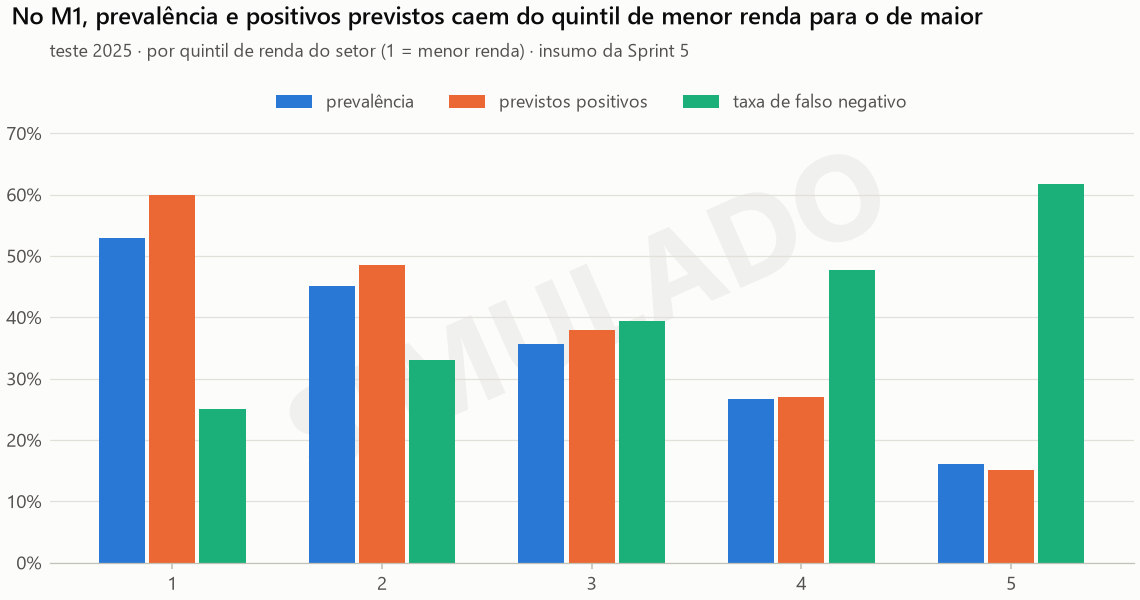

In [14]:
subgrupos = pd.concat([a.subgrupos for a in avaliacoes.values()], ignore_index=True)
display(subgrupos.loc[subgrupos["tarefa"] == "M1"].round(4))
fig = figuras.subgrupos(subgrupos.loc[subgrupos["tarefa"] == "M1"], "quintil_renda",
                        "No M1, prevalência e positivos previstos caem do quintil de menor renda para o de maior",
                        "teste 2025 · por quintil de renda do setor (1 = menor renda) · insumo da Sprint 5")
display(Image(filename=figuras.salvar(fig, FIGURAS, "08_subgrupos_m1.png")))

## 10. Pacote versionado e reprodutibilidade (E3)

O pacote reúne, para cada tarefa, o pipeline completo (imputação, escala, estimador e limiar), o contrato de atributos, as métricas, os metadados de linhagem e a ficha do modelo (Mitchell et al., 2019, DOI 10.1145/3287560.3287596), todos com SHA-256. O notebook grava o próprio pacote numa pasta de conferência e compara o hash de cada pipeline com o do pacote versionado em `models/sprint4/v1`, gerado por `treinar_sprint4.py`: se os bytes coincidem, o mesmo protocolo e a mesma base reproduziram o mesmo modelo. Em seguida, carrega o pacote versionado pela função que confere hash e versão do scikit-learn antes do `joblib.load`, porque a desserialização de pickle executa código e só pode ocorrer com arquivo de origem confiável (scikit-learn, "Model persistence").

In [15]:
pacote.empacotar(ctx, CONFERENCIA, treinos, avaliacoes)
conferencia, versionado = artefatos.ler_checksums(CONFERENCIA), artefatos.ler_checksums(VERSIONADO)
for nome in ("inadimplencia.joblib", "recuperabilidade.joblib"):
    print(f"{nome:26s} notebook {conferencia[nome][:16]}… · versionado {versionado[nome][:16]}… · iguais: {conferencia[nome] == versionado[nome]}")
recarregado = artefatos.carregar_modelo(VERSIONADO, "inadimplencia.joblib")
X_teste = dados.matriz(divisoes["M1"].conjuntos.teste, p.m1.atributos)
print("previsões do pacote versionado iguais às do notebook:",
      np.allclose(modelos.probabilidades(recarregado, X_teste), modelos.probabilidades(treinos["M1"].final, X_teste), atol=1e-12))
display(Markdown((VERSIONADO / "model_card.md").read_text(encoding="utf-8").split("## M1")[0]))

inadimplencia.joblib       notebook 5533b49c4e8a4ce5… · versionado 5533b49c4e8a4ce5… · iguais: True
recuperabilidade.joblib    notebook c139f6ca128ef4c9… · versionado c139f6ca128ef4c9… · iguais: True
previsões do pacote versionado iguais às do notebook: True


# Ficha do modelo — sprint4-v1

> Gerada por `pipeline/ml/documentos.py` na execução `20261108T041219-4306b3` (código `8c55960d30cee5004921b57efc5f4296b8e5f517`, protocolo 1.0.0). Dados individuais **sintéticos**: as métricas demonstram que o pipeline funciona, não que o modelo funciona no mundo real.

## Detalhes e uso pretendido

O pacote contém dois classificadores independentes, porque inadimplência e recuperabilidade diferem em população, momento de decisão e horizonte, e usar 1 − P(inadimplência) como recuperabilidade misturaria perguntas diferentes. Os dois são pipelines do scikit-learn 1.9.1 (imputação pela mediana do treino com indicador de ausência, escala só na logística e estimador), treinados com semente 20261107 em Python 3.14.7. O uso pretendido é apoio ao analista da Sefin em demonstração acadêmica: o M1 alimenta o mapa de risco e o M2 ordena a carteira de dívida ativa; nenhum dos dois decide cobrança, e nenhum deve ser usado com dados reais sem homologação, base legal e revisão humana.

## Fatores, dados e limites

Os dados de treino e de teste são créditos de IPTU simulados sobre os setores censitários reais de Palmas (base da Sprint 3, `c45d7ea9b875`, simulação `e66099c7d0c8`), e essa origem limita o que as métricas significam. A simulação usa probabilidade anual constante de recuperação depois da inscrição e calibra o valor lançado com a arrecadação real do próprio ano; por isso, o valor do lançamento corrente, a renda do Censo 2022 e os identificadores territoriais ficaram fora dos atributos, e a renda e a região foram guardadas só para a auditoria por subgrupo da Sprint 5. O valor relativo do imóvel continua como atributo e é um substituto (proxy) da renda do setor, de modo que retirar a renda direta não demonstra equidade.



## 11. Do modelo ao painel (E4)

O painel não treina nem reajusta nada: ele lê o lote ativo publicado por `treinar_sprint4.py`, que pontua com o pacote conferido a carteira inscrita e aberta em 31/07/2026, cujo desfecho em 365 dias ainda é futuro. O lote só é gerado se a definição dos modelos no protocolo atual for a registrada no pacote, e só é lido depois de conferidos o manifesto, o hash de cada arquivo e os modelos do pacote aprovado. O manifesto registra versões, protocolo aplicado, faixas, mínimo de suporte, exclusões e a conciliação entre a soma por crédito e a soma por devedor sintético (hipótese declarada: 1 imóvel = 1 devedor sintético, que não representa pessoa real).

In [16]:
from pipeline.ml import painel
lote = painel.carregar_lote(RAIZ / "reports" / "sprint4" / "lote", VERSIONADO)   # o mesmo caminho do painel
m2 = lote.manifesto["m2"]
print({k: m2[k] for k in ("fotografia", "horizonte_dias", "creditos", "devedores", "concilia")}, m2["exclusoes"])
proj = painel.projecao(lote.creditos)
print(f"principal em aberto {painel.reais(proj['principal_em_aberto_centavos'])} · valor esperado em 365 dias "
      f"{painel.reais(proj['valor_esperado_centavos'])} ({100 * proj['fracao_esperada']:.1f}%)")
display(painel.ranking(lote.devedores, "valor_esperado", 10))

{'fotografia': '2026-07-31', 'horizonte_dias': 365, 'creditos': 78122, 'devedores': 52510, 'concilia': True} {'a_vencer': 0, 'elegiveis_inscritos_e_abertos': 78122, 'pagos_ate_t0': 478138, 'total_base': 556260, 'vencidos_nao_inscritos': 0}
principal em aberto R$ 60.118.722,19 · valor esperado em 365 dias R$ 6.948.081,53 (11.6%)


,posicao,id_imovel,cd_setor,regiao,quintil_renda,creditos,principal_em_aberto_centavos,valor_esperado_centavos,score_devedor,faixa
0,1,65771,172100005000402,SUDESTE,5,2,2884684,234651,0.081344,BAIXA
1,2,53055,172100005000285,NORDESTE,5,4,2625536,234454,0.089298,BAIXA
2,3,108353,172100005000754,SUDOESTE,5,3,2394790,214628,0.089623,BAIXA
3,4,74661,172100005000485,SUDOESTE,5,2,4309394,203038,0.047115,BAIXA
4,5,52596,172100005000283,NORDESTE,5,3,2420617,202737,0.083754,BAIXA
5,6,81140,172100005000545,SUDOESTE,5,2,2280323,193829,0.085001,BAIXA
6,7,64085,172100005000387,SUDESTE,5,3,2218274,192011,0.086559,BAIXA
7,8,57846,172100005000330,SUDOESTE,5,2,2278722,190199,0.083467,BAIXA
8,9,63012,172100005000378,SUDESTE,5,2,2011843,188493,0.093691,BAIXA
9,10,103311,172100005000711,SUDESTE,3,5,2037800,186404,0.091474,BAIXA


## 12. Conclusão

O padrão comum às duas tarefas é que o pipeline respeita o tempo e mede o que a base permite medir. Para o M1, a base simulada contém sinal no histórico do imóvel, e o modelo o captura: Average Precision perto de 0,61 contra 0,37 do preditor constante, com o mesmo desempenho na validação e no teste e probabilidades calibradas no conjunto do teste, mas não em cada quintil de renda. A proximidade entre validação e teste é compatível com a ausência de vazamento, sem prová-la, porque um vazamento que atingisse os dois conjuntos daria números igualmente próximos; a evidência está nas regras de disponibilidade dos atributos e no caso sentinela da seção 4. Para o M2, a simulação não contém sinal, e o modelo, corretamente, não o inventa. Em ambos os casos, as métricas valem para o mundo sintético da Sprint 3 e demonstram o funcionamento técnico, não a eficácia da cobrança em Palmas.

As limitações também seguem do desenho dos dados. O valor do lançamento corrente foi calibrado com a arrecadação real do próprio ano, e a renda vem do Censo 2022, publicado depois de parte dos exercícios simulados; por isso, esses campos ficaram fora dos atributos, e o experimento deve ser lido como validação temporal em dados sintéticos retrospectivos. Uma avaliação de eficácia exigirá dados reais autorizados, um período posterior e separado do desenvolvimento e revisão humana das decisões de cobrança.

**Referências citadas neste notebook** (DOIs conferidos no Crossref em 07/11/2026; lista completa em `docs/sprint4/REFERENCIAS.md`): Amershi et al. (2019); Breiman (2001); Brier (1950); Collins et al. (2024); Hastie, Tibshirani e Friedman (2009); Kapoor e Narayanan (2023); Kaufman et al. (2012); Mitchell et al. (2019); Morris, White e Crowther (2019); NIST (2023); Roberts et al. (2017); Saito e Rehmsmeier (2015); Studer et al. (2021); Van Calster et al. (2019); Varma e Simon (2006); documentação do scikit-learn 1.9.1 (Common pitfalls; Cross-validation; Model persistence).